# Chapitre 11 - Cours 2 : stockage distribué, workflows et pannes

Les outils Unix s'arrêtent aux limites d'une machine. Pour traiter des téraoctets, il
faut répartir les données **et** le calcul sur un cluster. Ce cours présente les briques
d'un tel « système d'exploitation distribué » : un système de fichiers distribué qui
découpe et réplique les fichiers, un ordonnanceur qui enchaîne les jobs d'un workflow,
et une stratégie de tolérance aux pannes adaptée à des jobs qui durent des heures. Il
couvre la section *Batch Processing in Distributed Systems* (*Distributed Filesystems*, *Object Stores*, *Distributed Job Orchestration*, avec *Resource allocation*, *Scheduling workflows* et *Handling faults*).

**Plan.**

1. L'analogie du système d'exploitation distribué.
2. Le système de fichiers distribué : blocs, métadonnées, placement et localité.
3. Survivre aux pannes de disques : réplication ou codes d'effacement.
4. Les workflows : des graphes acycliques de jobs.
5. Pannes et préemption : relancer une tâche, pas tout le job.
6. Les magasins d'objets (object stores).
7. L'orchestration des jobs et l'allocation des ressources.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Un système d'exploitation distribué (section *Batch Processing in Distributed Systems*)

Sur la machine du cours 1, trois composants coopéraient : des **périphériques de
stockage** derrière l'interface du système de fichiers, un **ordonnanceur** du noyau qui
décide quel processus tourne sur quel cœur, et des **programmes** reliés par des
tuyaux. Un framework de traitement par lots distribué a exactement les mêmes
composants, à l'échelle d'un cluster. Le livre parle de **systèmes d'exploitation distribués** : un système de fichiers distribué ou un magasin d'objets, un orchestrateur de jobs (YARN, Kubernetes) et des tâches qui s'échangent des données par le stockage ou par le réseau.

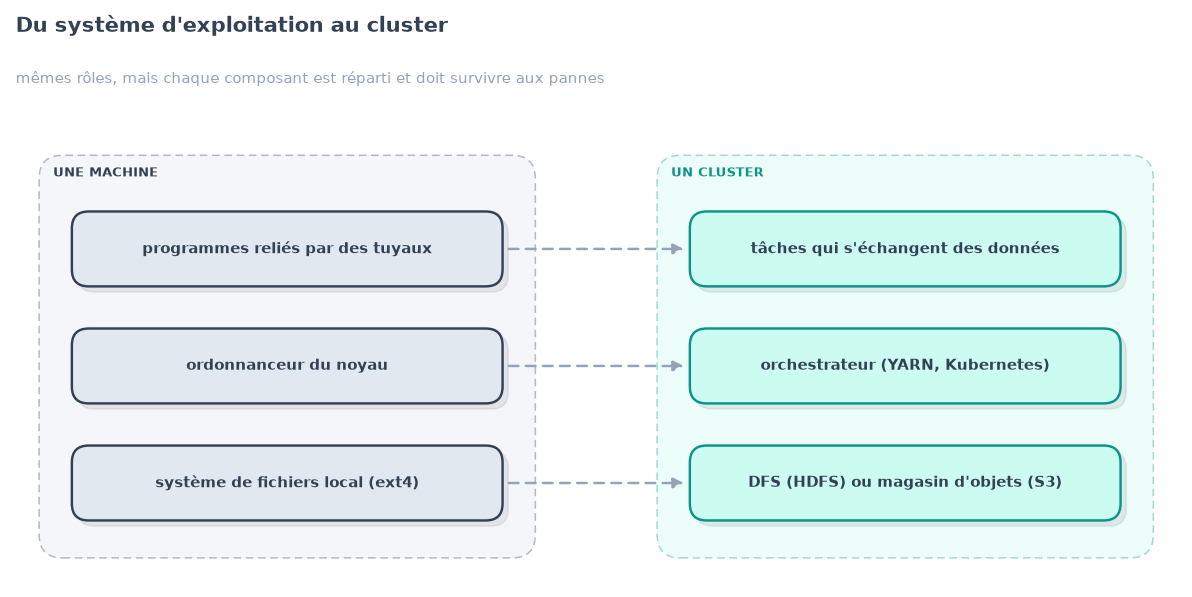

In [2]:
d = Diagram(12.5, 5.2, title="Du système d'exploitation au cluster",
            subtitle="mêmes rôles, mais chaque composant est réparti et doit survivre aux pannes")
d.group(0.3, 0.3, 5.6, 4.6, "une machine", color=SLATE)
d.group(6.9, 0.3, 12.2, 4.6, "un cluster", color=TEAL)
rows = [("programmes reliés par des tuyaux", "tâches qui s'échangent des données", 3.6),
        ("ordonnanceur du noyau", "orchestrateur (YARN, Kubernetes)", 2.35),
        ("système de fichiers local (ext4)", "DFS (HDFS) ou magasin d'objets (S3)", 1.1)]
for i, (a, b, y) in enumerate(rows):
    d.box(f"a{i}", 2.95, y, a, color=SLATE, w=4.6, h=0.8, fontsize=9.5)
    d.box(f"b{i}", 9.55, y, b, color=TEAL, w=4.6, h=0.8, fontsize=9.5)
    d.arrow(f"a{i}", f"b{i}", "", color=GRAY, style="dashed")
d.show()

> **À retenir.** Un framework de lots distribué est un « système d'exploitation » de
> cluster : un stockage partagé, un ordonnanceur, et des programmes qui se passent des
> données. Chaque brique doit en plus tolérer la panne d'une machine.

## 2. Le système de fichiers distribué (section *Distributed Filesystems*)

**Le principe.** Un système de fichiers distribué (DFS) comme HDFS découpe chaque
fichier en **blocs** et répartit ces blocs sur les disques des machines du cluster. Sur
chaque machine tourne un démon (*DataNode* dans HDFS) qui sert les blocs stockés
localement, comme des fichiers ordinaires de son système de fichiers. Un service
central, le **NameNode**, tient les **métadonnées** : quels blocs composent quel fichier,
et sur quelles machines se trouve chaque bloc. Un client demande au NameNode où lire, puis
lit directement les blocs auprès des DataNodes.

**Des blocs énormes.** Là où ext4 utilise des blocs de 4 Kio, HDFS utilise par défaut
**128 Mio**. Deux raisons : moins de blocs, donc moins de métadonnées (crucial à
l'échelle du pétaoctet, car le NameNode les garde en mémoire) ; et une lecture longue et
séquentielle par bloc, si bien que le temps d'accès devient négligeable devant le temps
de transfert. Le dernier bloc d'un fichier n'occupe que la place nécessaire.

fichier de 1 000 Mio en blocs de 128 Mio : [128, 128, 128, 128, 128, 128, 128, 104]


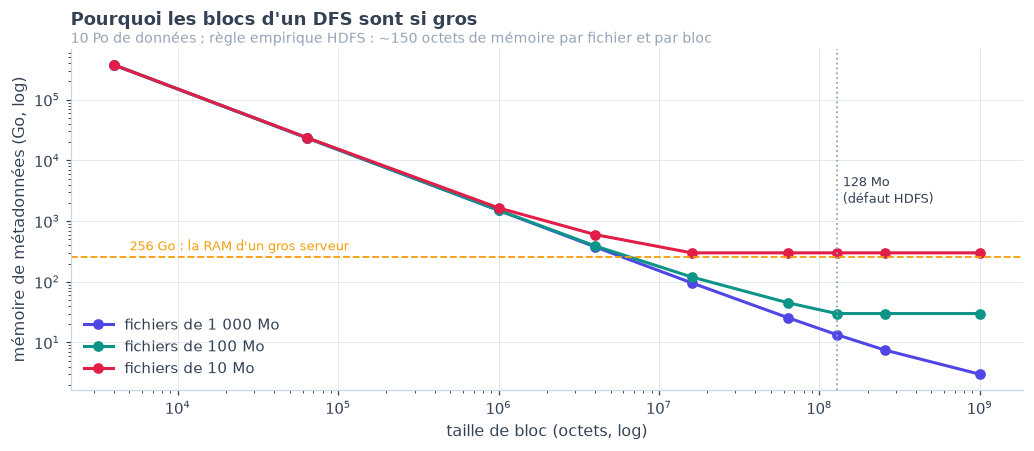

In [3]:
def blocs(taille_mio, bloc_mio=128):
    n_pleins, reste = divmod(taille_mio, bloc_mio)
    return [bloc_mio] * int(n_pleins) + ([reste] if reste else [])

print("fichier de 1 000 Mio en blocs de 128 Mio :", blocs(1000))

total = 10e15                      # 10 Po de données
taille_bloc = np.array([4e3, 64e3, 1e6, 4e6, 16e6, 64e6, 128e6, 256e6, 1e9])
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for fs, c in [(1e9, INDIGO), (100e6, TEAL), (10e6, ROSE)]:
    mem = [B.namenode_memory(total, b, fs) for b in taille_bloc]
    ax.loglog(taille_bloc, np.array(mem) / 1e9, "o-", color=c, label=f"fichiers de {fs / 1e6:,.0f} Mo".replace(",", " "))
ax.axvline(128e6, color=GRAY, ls=":", lw=1.2)
ax.text(140e6, 2e3, "128 Mo\n(défaut HDFS)", fontsize=8.5, color=SLATE)
ax.axhline(256, color=AMBER, ls="--", lw=1.2)
ax.text(5e3, 330, "256 Go : la RAM d'un gros serveur", fontsize=8.5, color=AMBER)
ax.set_xlabel("taille de bloc (octets, log)"); ax.set_ylabel("mémoire de métadonnées (Go, log)")
ax.set_title("Pourquoi les blocs d'un DFS sont si gros")
subtitle(ax, "10 Po de données ; règle empirique HDFS : ~150 octets de mémoire par fichier et par bloc")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

Avec des blocs de 4 Kio, les métadonnées de 10 Po demanderaient des centaines de
téraoctets de RAM ; avec 128 Mo, il en faut de 13 à 300 Go selon la taille des fichiers. La figure
montre aussi le talon d'Achille du NameNode : au-delà d'une certaine taille de bloc, ce
sont les **petits fichiers** qui dominent (un fichier coûte au moins une entrée, quelle
que soit sa taille). D'où la consigne classique : produire peu de gros fichiers.

**Placement des répliques.** Pour survivre à la panne d'une machine, chaque bloc est
copié sur plusieurs DataNodes (3 par défaut). La politique de HDFS tient compte des
**racks** (armoires partageant un commutateur et une alimentation) : la première copie
sur un nœud, la deuxième sur un **autre rack**, la troisième sur le même rack que la
deuxième. Une panne de rack entier ne détruit donc jamais toutes les copies, tout en
limitant le trafic entre racks à l'écriture. Simulons ce placement sur 4 racks de 10
machines.

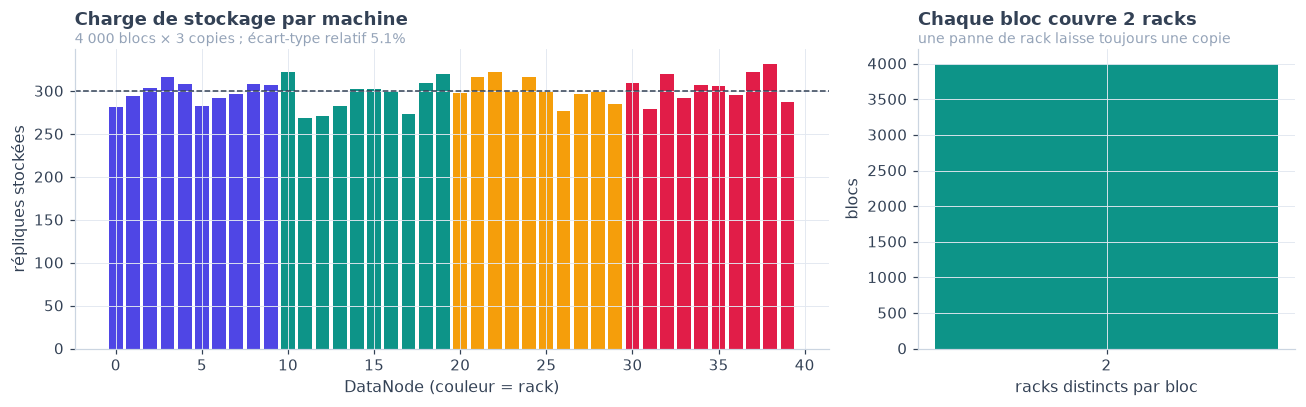

In [4]:
n_nodes, par_rack = 40, 10
pl = B.place_blocks(4000, n_nodes, 3, nodes_per_rack=par_rack, seed=1)
par_noeud = np.bincount(pl.ravel(), minlength=n_nodes)
racks_par_bloc = np.array([len({B.rack_of(int(x), par_rack) for x in b}) for b in pl])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(range(n_nodes), par_noeud, color=[COLORS[B.rack_of(i, par_rack)] for i in range(n_nodes)])
axes[0].axhline(par_noeud.mean(), color=SLATE, ls="--", lw=1)
axes[0].set_xlabel("DataNode (couleur = rack)"); axes[0].set_ylabel("répliques stockées")
axes[0].set_title("Charge de stockage par machine")
subtitle(axes[0], f"4 000 blocs × 3 copies ; écart-type relatif {par_noeud.std() / par_noeud.mean():.1%}")
vals, cnt = np.unique(racks_par_bloc, return_counts=True)
axes[1].bar([str(v) for v in vals], cnt, color=TEAL)
axes[1].set_xlabel("racks distincts par bloc"); axes[1].set_ylabel("blocs")
axes[1].set_title("Chaque bloc couvre 2 racks")
subtitle(axes[1], "une panne de rack laisse toujours une copie")
plt.tight_layout(); plt.show()

**Localité des données.** Puisque chaque bloc existe en plusieurs exemplaires,
l'ordonnanceur peut lancer la tâche qui lit un bloc **sur une des machines qui le
détiennent** : la lecture se fait alors sur le disque local, sans traverser le réseau.
C'est le principe « déplacer le calcul vers les données » : le code d'une tâche pèse
quelques mégaoctets, son entrée 128 Mo. Mais si ces machines sont déjà occupées par
d'autres jobs, la tâche part ailleurs, de préférence sur le même rack. La simulation
mesure la part de tâches locales selon l'occupation du cluster et le nombre de copies.

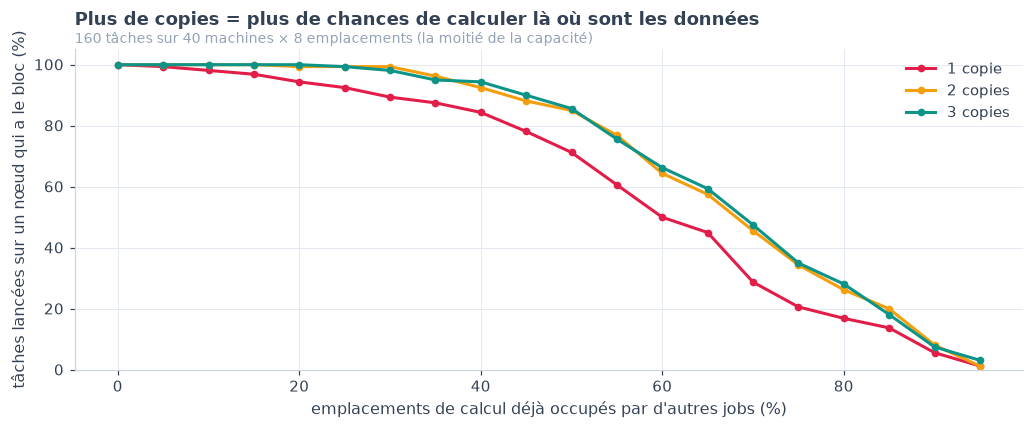

In [5]:
busy = np.linspace(0, 0.95, 20)
fig, ax = plt.subplots(figsize=(9.5, 4))
for r, c in [(1, ROSE), (2, AMBER), (3, TEAL)]:
    plr = B.place_blocks(160, n_nodes, r, nodes_per_rack=par_rack, seed=2)
    loc = [B.schedule_locality(plr, n_nodes, slots_per_node=8, busy_fraction=b, nodes_per_rack=par_rack, seed=3)["nœud"]
           for b in busy]
    ax.plot(busy * 100, np.array(loc) * 100, "o-", ms=4, color=c, label=f"{r} copie{'s' if r > 1 else ''}")
ax.set_xlabel("emplacements de calcul déjà occupés par d'autres jobs (%)")
ax.set_ylabel("tâches lancées sur un nœud qui a le bloc (%)")
ax.set_ylim(0, 105)
ax.set_title("Plus de copies = plus de chances de calculer là où sont les données")
subtitle(ax, "160 tâches sur 40 machines × 8 emplacements (la moitié de la capacité)")
ax.legend()
plt.tight_layout(); plt.show()

Avec une seule copie, la localité baisse dès que le cluster est un peu chargé : il suffit
que l'unique machine qui détient le bloc soit pleine. Avec deux ou trois copies,
l'ordonnanceur a le choix et la chute est retardée (85 % de tâches locales à 50 %
d'occupation, contre 70 % avec une copie) ; quand le cluster est presque plein, plus
personne n'est local et les lectures passent par le réseau, de préférence à l'intérieur
du rack. La réplication sert donc deux fois : à la
durabilité et à la souplesse de l'ordonnancement.

> **À retenir.** Un DFS découpe les fichiers en gros blocs (128 Mo), répliqués sur
> plusieurs machines et plusieurs racks ; un service de métadonnées (le NameNode) sait où
> est chaque bloc. Les gros blocs limitent les métadonnées, les copies permettent de
> lancer les tâches là où sont les données.

## 3. Survivre aux pannes de disques : réplication ou codes d'effacement

Les DFS tournent sur du matériel ordinaire, moins cher mais moins fiable que du matériel
haut de gamme : des disques et des machines tombent en panne en permanence. Deux façons
de ne rien perdre :

- la **réplication** : $r$ copies complètes de chaque bloc (chapitre 6) ;
  on perd un bloc si les $r$ copies disparaissent avant d'avoir été refaites ; coût de
  stockage : $r$ ;
- les **codes d'effacement** (*erasure coding*, par exemple Reed-Solomon) : on découpe
  un bloc en $k$ fragments et on calcule $m$ fragments de **parité** ; n'importe quels
  $k$ fragments parmi les $k+m$ suffisent à tout reconstruire. Coût : $(k+m)/k$. C'est
  le principe des grappes RAID, mais à travers le réseau du centre de données, sans
  matériel spécial.

Le cas le plus simple est $m = 1$ : la parité est le **XOR** des $k$ fragments. Si un
fragment disparaît, le XOR des survivants et de la parité le redonne, car
$a \oplus a = 0$.

In [6]:
rng = np.random.default_rng(7)
fragments = [rng.integers(0, 256, 16, dtype=np.uint8).tobytes() for _ in range(4)]
parite = B.xor_parity(fragments)
perdu = 2
reconstruit = B.xor_recover([f for i, f in enumerate(fragments) if i != perdu], parite)
pd.DataFrame({"fragment": [f"d{i}" for i in range(4)] + ["parité"],
              "octets (hex)": [f.hex(" ") for f in fragments + [parite]]}).assign(
    statut=["", "", "PERDU, reconstruit" if reconstruit == fragments[perdu] else "erreur", "", ""])

,fragment,octets (hex),statut
0,d0,8b 4a e5 f1 a9 41 06 a0 95 6a 26 af bc cd af e5,
1,d1,62 f9 0a 94 5f 56 93 c6 42 27 6a d5 ab 2d a7 39,
2,d2,45 51 37 0e 99 b2 d7 4c 34 27 fa 48 d7 32 a1 df,"PERDU, reconstruit"
3,d3,70 ac a1 e9 26 11 59 01 dd 06 f2 7f 8f 06 3c d2,
4,parité,dc 4e 79 82 49 b4 1b 2b 3e 6c 44 4d 4f d4 95 d1,


Reed-Solomon généralise ce calcul (arithmétique dans un corps fini) pour tolérer $m$
pertes quelconques. Comparons la probabilité de perdre un bloc en supposant que chaque
fragment est perdu, indépendamment, avec une probabilité $p$ avant d'être réparé :
réplication $p^r$, code $(k, m)$ : probabilité que plus de $m$ des $k+m$ fragments
soient perdus (loi binomiale).

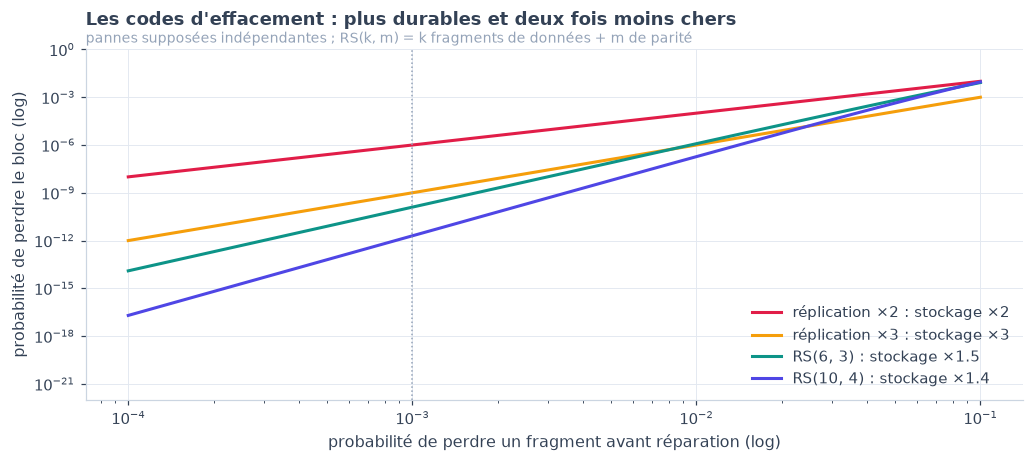

,coût de stockage,"P(perte) si p = 0,001"
schéma,,
réplication ×2,2.0,1.000e-06
réplication ×3,3.0,1.000e-09
"RS(6, 3)",1.5,1.255e-10
"RS(10, 4)",1.4,1.987e-12


In [7]:
p = np.logspace(-4, -1, 50)
schemas = [("réplication ×2", lambda p: B.p_loss_replication(p, 2), 2.0, ROSE),
           ("réplication ×3", lambda p: B.p_loss_replication(p, 3), 3.0, AMBER),
           ("RS(6, 3)", lambda p: B.p_loss_erasure(p, 6, 3), 1.5, TEAL),
           ("RS(10, 4)", lambda p: B.p_loss_erasure(p, 10, 4), 1.4, INDIGO)]
fig, ax = plt.subplots(figsize=(9.5, 4.3))
for nom, f, cout, c in schemas:
    ax.loglog(p, [f(x) for x in p], color=c, label=f"{nom} : stockage ×{cout:g}")
ax.axvline(1e-3, color=GRAY, ls=":", lw=1)
ax.set_xlabel("probabilité de perdre un fragment avant réparation (log)")
ax.set_ylabel("probabilité de perdre le bloc (log)")
ax.set_ylim(1e-22, 1)
ax.set_title("Les codes d'effacement : plus durables et deux fois moins chers")
subtitle(ax, "pannes supposées indépendantes ; RS(k, m) = k fragments de données + m de parité")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
pd.DataFrame([(nom, cout, f(1e-3)) for nom, f, cout, _ in schemas],
             columns=["schéma", "coût de stockage", "P(perte) si p = 0,001"]).set_index("schéma")

Pour $p = 10^{-3}$, RS(6, 3) perd un bloc avec une probabilité de l'ordre de $10^{-10}$,
bien moins que la triple réplication ($10^{-9}$), pour moitié moins de disque. Le prix est
ailleurs : reconstruire un fragment demande de lire $k$ autres fragments sur $k$
machines (trafic réseau et calcul), et une lecture normale doit assembler plusieurs
fragments au lieu de lire une copie locale. On réserve donc souvent les codes
d'effacement aux données froides, et la réplication aux données chaudes. Rappelons aussi
que l'hypothèse d'indépendance est optimiste (chapitre 2 : les pannes
corrélées dominent en pratique).

**Rien de partagé.** Un DFS suit l'architecture **shared-nothing** (aucune ressource
partagée entre les machines, seulement un réseau ordinaire), à l'opposé des baies de
stockage NAS ou SAN, qui centralisent les disques dans un équipement spécialisé relié par
un réseau dédié (Fibre Channel) : c'est une architecture à disques partagés.

> **À retenir.** Réplication ($r$ copies, coût $r$) ou codes d'effacement ($k+m$
> fragments, coût $(k+m)/k$) : les seconds offrent une durabilité comparable ou
> meilleure pour bien moins de stockage, au prix de reconstructions plus coûteuses en
> réseau.

## 4. Les workflows : des graphes acycliques de jobs (section *Scheduling workflows*)

Un seul job répond rarement à toute une question : la sortie d'un job devient l'entrée
d'un ou plusieurs autres, et un job peut avoir plusieurs entrées produites par
d'autres. On obtient un **workflow**, c'est-à-dire un graphe orienté acyclique (DAG) de
jobs, comme les commandes d'un pipeline Unix mais en plus général. On découpe ainsi le
travail parce que :

- plusieurs équipes consomment la même sortie : le premier job l'écrit à un endroit
  connu, chaque consommateur la lit à son rythme ;
- on passe d'un outil à un autre (un job écrit des fichiers, un autre outil les lit) ;
- un traitement a besoin de plusieurs étapes partitionnées différemment (une étape par
  utilisateur, la suivante par URL, par exemple).

Contrairement aux tuyaux Unix, la sortie d'un job est le plus souvent **écrite dans le
DFS**, et le job suivant ne démarre qu'une fois **toutes** ses entrées terminées avec
succès. Ce découplage permet de relancer un job isolément. L'ordonnanceur du cluster ne
gère qu'un job à la fois ; les dépendances sont confiées à un **ordonnanceur de
workflows** (Airflow, Dagster, Prefect, qui ont remplacé Oozie et Azkaban, liés à Hadoop), qui offre aussi
l'historique, les relances et la visualisation. Des workflows de 50 à 100 jobs sont
courants. Voici un exemple plus modeste : la chaîne quotidienne qui produit les
recommandations d'un site marchand.

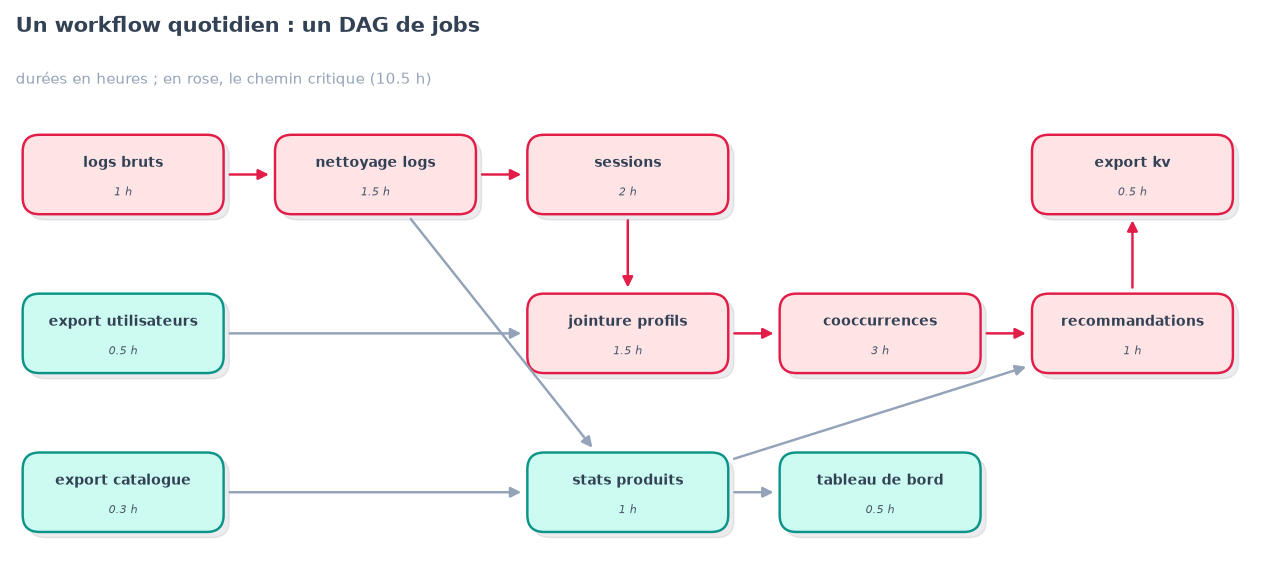

In [8]:
wf = B.Workflow()
wf.add("logs_bruts", 1.0).add("export_utilisateurs", 0.5).add("export_catalogue", 0.3)
wf.add("nettoyage_logs", 1.5, ["logs_bruts"])
wf.add("sessions", 2.0, ["nettoyage_logs"])
wf.add("jointure_profils", 1.5, ["sessions", "export_utilisateurs"])
wf.add("stats_produits", 1.0, ["nettoyage_logs", "export_catalogue"])
wf.add("cooccurrences", 3.0, ["jointure_profils"])
wf.add("tableau_de_bord", 0.5, ["stats_produits"])
wf.add("recommandations", 1.0, ["cooccurrences", "stats_produits"])
wf.add("export_kv", 0.5, ["recommandations"])
chemin, duree_min = wf.critical_path()

pos = {"logs_bruts": (1.2, 4.2), "export_utilisateurs": (1.2, 2.5), "export_catalogue": (1.2, 0.8),
       "nettoyage_logs": (3.9, 4.2), "sessions": (6.6, 4.2), "jointure_profils": (6.6, 2.5),
       "stats_produits": (6.6, 0.8), "cooccurrences": (9.3, 2.5), "tableau_de_bord": (9.3, 0.8),
       "recommandations": (12.0, 2.5), "export_kv": (12.0, 4.2)}
d = Diagram(13.3, 5.0, title="Un workflow quotidien : un DAG de jobs",
            subtitle=f"durées en heures ; en rose, le chemin critique ({duree_min:.1f} h)")
for j, (x, y) in pos.items():
    d.box(j, x, y, j.replace("_", " "), sub=f"{wf.duration[j]:g} h", color=ROSE if j in chemin else TEAL,
          w=2.15, h=0.85, fontsize=9)
for j, deps in wf.deps.items():
    for dep in deps:
        crit = dep in chemin and j in chemin and chemin.index(j) == chemin.index(dep) + 1
        d.arrow(dep, j, "", color=ROSE if crit else GRAY)
d.show()

L'ordre topologique donne une séquence valide ; le **chemin critique** (le plus long
chemin du DAG) donne la durée minimale du workflow, même avec des ressources illimitées.
Le diagramme de Gantt compare une exécution avec ressources illimitées, une exécution sur
deux emplacements seulement, et une exécution où `sessions` échoue une fois (panne
transitoire) puis réussit à la relance.

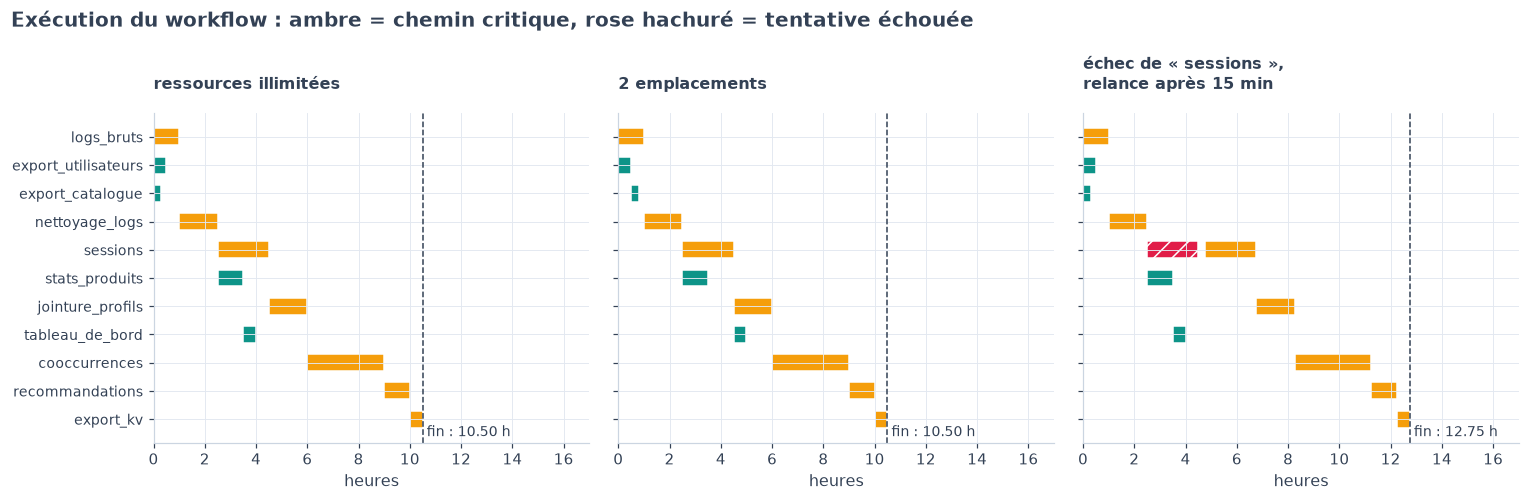

chemin critique : logs_bruts -> nettoyage_logs -> sessions -> jointure_profils -> cooccurrences -> recommandations -> export_kv (10.5 h)
jobs à relancer si « sessions » produit une sortie fausse : ['jointure_profils', 'cooccurrences', 'recommandations', 'export_kv']


In [9]:
scen = {"ressources illimitées": wf.schedule(),
        "2 emplacements": wf.schedule(slots=2),
        "échec de « sessions »,\nrelance après 15 min": wf.schedule(attempts={"sessions": 1}, retry_delay=0.25)}
ordre = wf.topo_order()
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, (nom, rows) in zip(axes, scen.items()):
    for r in rows:
        y = ordre.index(r["job"])
        c = ROSE if not r["succes"] else (AMBER if r["job"] in chemin else TEAL)
        ax.barh(y, r["fin"] - r["debut"], left=r["debut"], color=c, height=0.6,
                hatch="//" if not r["succes"] else None, edgecolor="white")
    fin = max(r["fin"] for r in rows)
    ax.axvline(fin, color=SLATE, ls="--", lw=1)
    ax.set_title(nom, fontsize=10.5)
    ax.text(fin, len(ordre) - 0.4, f" fin : {fin:.2f} h", fontsize=9, color=SLATE)
    ax.set_xlabel("heures"); ax.set_xlim(0, 17)
axes[0].set_yticks(range(len(ordre))); axes[0].set_yticklabels(ordre, fontsize=9); axes[0].invert_yaxis()
finish(fig, "Exécution du workflow : ambre = chemin critique, rose hachuré = tentative échouée")
plt.show()
print("chemin critique :", " -> ".join(chemin), f"({duree_min:.1f} h)")
print("jobs à relancer si « sessions » produit une sortie fausse :", wf.downstream("sessions"))

Avec des ressources illimitées, le workflow dure exactement la longueur du chemin
critique. Avec deux emplacements seulement, il finit à la même heure : les jobs hors du
chemin critique ont de la **marge** et se glissent dans les trous (`export_catalogue`
et `stats_produits` démarrent un peu plus tard sans rien retarder). Ajouter des machines
n'accélère donc pas un workflow au-delà de son chemin critique ; il faut raccourcir les
jobs de ce chemin. L'échec d'un job du chemin critique retarde toute la fin du
workflow de la durée de la tentative perdue, mais rien n'est à refaire en amont :
les entrées de `sessions` sont intactes dans le DFS. Si l'on découvre plus tard que
`sessions` était **bogué**, il suffit de corriger et de relancer ce job et ses
descendants (`wf.downstream`), puisque chaque sortie est un fichier immuable recalculable. Attention au vocabulaire : les moteurs d'exécution durable vus au chapitre 5 parlent aussi de « workflows », mais au sens d'une suite d'appels de services ; ici, un workflow enchaîne des jobs qui lisent et écrivent des fichiers.

> **À retenir.** Un workflow est un DAG de jobs dont les sorties intermédiaires sont
> matérialisées dans le stockage distribué. Un ordonnanceur de workflows lance chaque
> job quand ses entrées sont prêtes, relance les échecs, et permet de recalculer
> seulement le sous-graphe touché par un bogue. La durée minimale est celle du chemin
> critique.

## 5. Pannes et préemption (section *Handling faults*)

Un job qui dure des heures sur des centaines de machines connaîtra presque sûrement au
moins une panne de tâche : disque, machine, réseau. S'y ajoute une cause bien plus
fréquente : la **préemption**. Pour mieux remplir ses machines, un cluster partagé fait
tourner des tâches de basse priorité dans les creux, quitte à les tuer quand une tâche
prioritaire arrive. Le livre cite le cas de Google, où une tâche de lots d'une heure
avait environ 5 % de risque d'être tuée ainsi : bien plus que les pannes matérielles.

**Relancer depuis le début.** Comme un job de lots recalcule sa sortie à partir d'une
entrée immuable, une tâche interrompue se relance simplement ailleurs, après effacement
de sa sortie partielle. Si les interruptions forment un processus de Poisson de taux
$\lambda$ et qu'une tâche dure $T$ sans interruption, sa durée moyenne avec relances
vaut
$$\mathbb{E}[D] = \frac{e^{\lambda T} - 1}{\lambda} \approx T\left(1 + \frac{\lambda T}{2}\right)\ \text{si}\ \lambda T \ll 1.$$
*Démonstration.* Soit $D$ la durée totale. Avec probabilité $e^{-\lambda T}$, aucune
interruption : $D = T$. Sinon, on perd un temps $X$ (instant de l'interruption,
conditionné à $X < T$), puis on recommence à zéro. D'où
$\mathbb{E}[D] = e^{-\lambda T}\,T + (1 - e^{-\lambda T})\left(\mathbb{E}[X \mid X<T] + \mathbb{E}[D]\right)$,
et le calcul de $\mathbb{E}[X \mid X<T]$ pour une loi exponentielle donne la formule.
Le coût croît **exponentiellement** avec la longueur des tâches : c'est pourquoi on
découpe un job en nombreuses tâches courtes et indépendantes, et qu'on ne relance que
la tâche touchée, jamais tout le job.

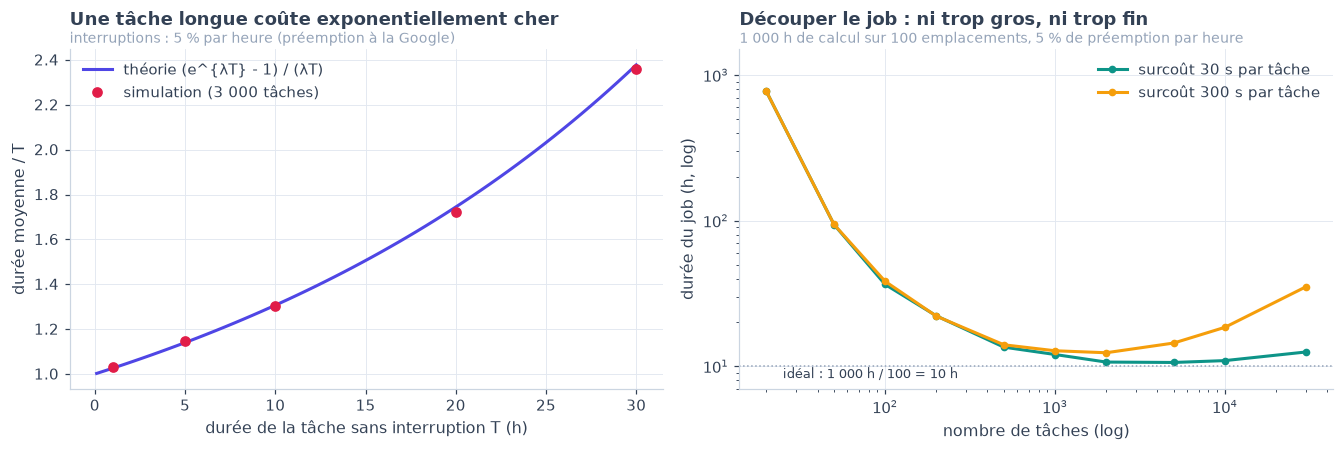

In [10]:
lam = -math.log(0.95)              # 5 % de risque d'être tuée en une heure
T = np.linspace(0.1, 30, 60)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
theo = np.array([B.expected_time_with_restarts(t, lam) for t in T])
axes[0].plot(T, theo / T, color=INDIGO, label="théorie (e^{λT} - 1) / (λT)")
Ts = [1, 5, 10, 20, 30]
sim = [B.simulate_restarts(t, lam, 3000, seed=int(t)).mean() / t for t in Ts]
axes[0].plot(Ts, sim, "o", color=ROSE, label="simulation (3 000 tâches)")
axes[0].set_xlabel("durée de la tâche sans interruption T (h)"); axes[0].set_ylabel("durée moyenne / T")
axes[0].set_title("Une tâche longue coûte exponentiellement cher")
subtitle(axes[0], "interruptions : 5 % par heure (préemption à la Google)")
axes[0].legend()
# un job de 1 000 heures de calcul sur 100 emplacements, surcoût de 30 s par tentative
n_taches = np.array([20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 30000])
for over, c in [(30 / 3600, TEAL), (5 / 60, AMBER)]:
    mk = [np.mean([B.simulate_job(1000, int(n), 100, lam, overhead=over, seed=s) for s in range(3)]) for n in n_taches]
    axes[1].loglog(n_taches, mk, "o-", ms=4, color=c, label=f"surcoût {over * 3600:.0f} s par tâche")
axes[1].axhline(10, color=GRAY, ls=":", lw=1)
axes[1].text(25, 8.3, "idéal : 1 000 h / 100 = 10 h", fontsize=8.5, color=SLATE)
axes[1].set_xlabel("nombre de tâches (log)"); axes[1].set_ylabel("durée du job (h, log)")
axes[1].set_ylim(7, 1500)
axes[1].set_title("Découper le job : ni trop gros, ni trop fin")
subtitle(axes[1], "1 000 h de calcul sur 100 emplacements, 5 % de préemption par heure")
axes[1].legend()
plt.tight_layout(); plt.show()

La simulation suit la formule. À droite apparaît le compromis de **granularité** : avec
20 tâches de 50 heures, chacune est relancée de nombreuses fois (une tâche de 50 h a
moins de 8 % de chances de finir sans interruption) et seuls 20 des 100 emplacements
travaillent : le job dure plus de 700 heures ; avec des dizaines de milliers de tâches minuscules, le
surcoût de démarrage de chaque tâche domine. Entre les deux, un large plateau proche de
l'idéal.

**Le cas des étapes enchaînées.** Une tâche qui lit la sortie d'une autre ne peut
démarrer que si cette sortie existe et est complète. MapReduce écrit toujours les
données intermédiaires dans le DFS et attend la fin de la tâche productrice : coûteux en
écritures, mais une préemption ne fait perdre que la tâche en cours. Le diagramme montre
une tâche tuée par préemption et relancée sur une autre machine ; sa sortie n'est
publiée (renommée à sa place définitive) qu'à la fin d'une tentative réussie.

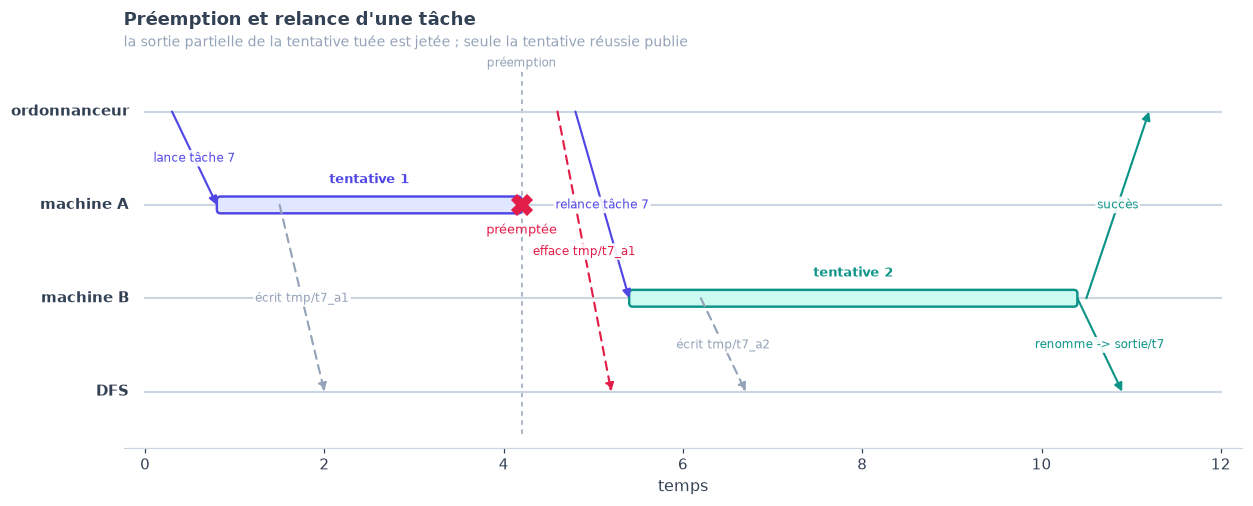

In [11]:
st = SpaceTime(["ordonnanceur", "machine A", "machine B", "DFS"], t_max=12, width=11.5,
               title="Préemption et relance d'une tâche",
               subtitle="la sortie partielle de la tentative tuée est jetée ; seule la tentative réussie publie")
st.msg("ordonnanceur", 0.3, "machine A", 0.8, "lance tâche 7", color=INDIGO)
st.op("machine A", 0.8, 4.2, "tentative 1", color=INDIGO)
st.msg("machine A", 1.5, "DFS", 2.0, "écrit tmp/t7_a1", color=GRAY, style="dashed")
st.event("machine A", 4.2, "préemptée", kind="crash")
st.msg("ordonnanceur", 4.6, "DFS", 5.2, "efface tmp/t7_a1", color=ROSE, style="dashed")
st.msg("ordonnanceur", 4.8, "machine B", 5.4, "relance tâche 7", color=INDIGO)
st.op("machine B", 5.4, 10.4, "tentative 2", color=TEAL)
st.msg("machine B", 6.2, "DFS", 6.7, "écrit tmp/t7_a2", color=GRAY, style="dashed")
st.msg("machine B", 10.4, "DFS", 10.9, "renomme -> sortie/t7", color=TEAL)
st.msg("machine B", 10.5, "ordonnanceur", 11.2, "succès", color=TEAL)
st.vline(4.2, "préemption")
st.show()

> **À retenir.** Dans un cluster partagé, la préemption des tâches de basse priorité est
> plus fréquente que les pannes matérielles. Comme une tâche est déterministe et lit une
> entrée immuable, on la relance simplement, et seulement elle. Le temps perdu croît
> exponentiellement avec la durée des tâches : on découpe les jobs en tâches courtes.

**Instances préemptibles.** Le livre souligne que les clouds vendent cette capacité de
basse priorité à prix réduit : *spot instances* chez AWS, *spot VMs* chez Azure,
*preemptible instances* chez Google Cloud. Un job de lots tolérant aux préemptions peut
en profiter. Faisons le calcul pour le job ci-dessus (1 000 tâches) : la machine
préemptible coûte 30 % du prix normal mais subit, disons, 15 % d'interruptions par heure
au lieu de 1 %.

In [12]:
rows = []
for nom, prix, lam_ in [("à la demande", 1.0, -math.log(0.99)), ("préemptible", 0.3, -math.log(0.85))]:
    duree = np.mean([B.simulate_job(1000, 1000, 100, lam_, overhead=30 / 3600, seed=s) for s in range(5)])
    heures_payees = 1000 * B.expected_time_with_restarts(1.0 + 30 / 3600, lam_)
    rows.append({"type de machine": nom, "prix relatif / h": prix, "interruptions / h": f"{1 - math.exp(-lam_):.0%}",
                 "durée du job (h)": duree, "heures-machine payées": heures_payees,
                 "coût relatif": heures_payees * prix})
S = pd.DataFrame(rows).set_index("type de machine")
S["coût relatif"] /= S["coût relatif"].iloc[0]
S.round(2)

,prix relatif / h,interruptions / h,durée du job (h),heures-machine payées,coût relatif
type de machine,,,,,
à la demande,1.0,1%,11.30,1013.46,1.00
préemptible,0.3,15%,12.58,1095.66,0.32


Les interruptions plus fréquentes rallongent un peu le job (une tâche sur sept environ
recommence), mais la facture tombe à moins d'un tiers : c'est pourquoi le traitement par
lots, rarement pressé, est le client idéal des capacités préemptibles.

## 6. Les magasins d'objets (section *Object Stores*)

Dans le cloud, le stockage des jobs de lots a largement migré des DFS vers les
**magasins d'objets** (*object stores*) : Amazon S3, Google Cloud Storage, Azure Blob
Storage. Ils ressemblent à un système de fichiers mais en diffèrent sur des points qui
comptent pour un job de lots :

- un objet est désigné par un **bucket** et une **clé** (`s3://bucket/2025/04/01/a.png`) ;
  on l'écrit en entier (`put`) et on le lit (`get`) ; il est **immuable** : pour le
  modifier, on le réécrit entièrement, comme dans un magasin clé-valeur ;
- il n'y a **pas de répertoires** : les « / » font partie de la clé. Lister un préfixe
  renvoie récursivement tous les objets dessous (comme `ls -R`), et un « répertoire »
  disparaît dès que son dernier objet est supprimé ;
- pas de liens, pas de verrous, et surtout **pas de renommage atomique** : renommer,
  c'est copier puis supprimer, objet par objet ;
- le stockage est **séparé du calcul** : pas de localité des données, mais calcul et
  stockage se dimensionnent indépendamment, et les réseaux modernes sont assez rapides.

`ddia.batch_modern.ObjectStore` simule ces règles. Le piège classique : un job écrit ses
fichiers dans un répertoire temporaire puis le « renomme » pour publier sa sortie, comme
on le faisait sur HDFS. Que se passe-t-il si le client meurt au milieu ?

In [13]:
from ddia import batch_modern as BM

s3 = BM.ObjectStore()
for i in range(8):
    s3.put("lots", f"sortie/_tmp/part-{i:05d}", f"données {i}".encode())
print("liste du préfixe sortie/ :", len(s3.list("lots", "sortie/")), "objets ;",
      "« répertoires » :", s3.list_dirs("lots", "sortie/"))
try:
    s3.rename_prefix("lots", "sortie/_tmp/", "sortie/final/", crash_after=5)
except BM.RenameInterrupted as e:
    print("renommage :", e)
etat = pd.DataFrame({"clé": s3.list("lots", "sortie/")})
etat["visible par un lecteur de sortie/final/ ?"] = etat["clé"].str.startswith("sortie/final/")
etat

liste du préfixe sortie/ : 8 objets ; « répertoires » : ['sortie/_tmp/']
renommage : interrompu après 5 objets


,clé,visible par un lecteur de sortie/final/ ?
0,sortie/_tmp/part-00005,False
1,sortie/_tmp/part-00006,False
2,sortie/_tmp/part-00007,False
3,sortie/final/part-00000,True
4,sortie/final/part-00001,True
5,sortie/final/part-00002,True
6,sortie/final/part-00003,True
7,sortie/final/part-00004,True


Un lecteur de `sortie/final/` voit 5 fichiers sur 8 : une sortie **partielle**, sans
aucun moyen de le savoir. La solution, adoptée par les formats de tables ouverts vus au
chapitre 4, est de ne jamais renommer : chaque tentative écrit sous un
préfixe qui lui est propre, puis publie un **manifeste** (la liste des fichiers) et un
pointeur, chacun en **un seul** `put`, atomique. L'exercice 11.12 approfondit ce
protocole. Comparons enfin le nombre de requêtes d'un « renommage » de répertoire selon
le nombre de fichiers : sur un DFS, c'est une seule opération de métadonnées.

In [14]:
rows = []
for n in [10, 100, 1000, 10000]:
    s = BM.ObjectStore()
    for i in range(n):
        s.put("b", f"t/_tmp/p{i}", b"x")
    s.reset_requests()
    s.rename_prefix("b", "t/_tmp/", "t/final/")
    rows.append({"fichiers": n, "requêtes (LIST + COPY + DELETE)": sum(s.requests.values()),
                 "durée à 20 ms par requête (s)": sum(s.requests.values()) * 0.02})
pd.DataFrame(rows).set_index("fichiers")

,requêtes (LIST + COPY + DELETE),durée à 20 ms par requête (s)
fichiers,,
10,21,0.42
100,201,4.02
1000,2001,40.02
10000,20010,400.20


> **À retenir.** Un magasin d'objets offre des objets immuables adressés par clé, une
> liste par préfixe et une séparation complète du calcul et du stockage, mais ni
> répertoires ni renommage atomique. Un job qui publie sa sortie doit donc s'appuyer sur
> l'atomicité d'**un** `put` (manifeste, pointeur), pas sur un renommage.

## 7. L'orchestration des jobs et l'allocation des ressources (section *Distributed Job Orchestration*)

Lancer un job sur un cluster, c'est ce que fait le noyau sur une machine, mais réparti.
Le framework envoie à l'**orchestrateur** (YARN, Kubernetes) une demande : nombre de
tâches, CPU, mémoire et disque par tâche, matériel requis (GPU), emplacement du code,
paramètres d'entrée et de sortie, identifiants d'accès. Trois composants s'en chargent :

- des **exécuteurs** sur chaque nœud (NodeManager pour YARN, kubelet pour Kubernetes)
  qui démarrent les tâches, les isolent (cgroups Linux) et signalent leur santé par des
  battements de cœur ;
- un **gestionnaire de ressources** qui tient la vue globale de l'état du cluster
  (stockée dans ZooKeeper ou etcd, chapitre 10) ;
- un **ordonnanceur** qui décide quelle tâche tourne sur quel nœud.

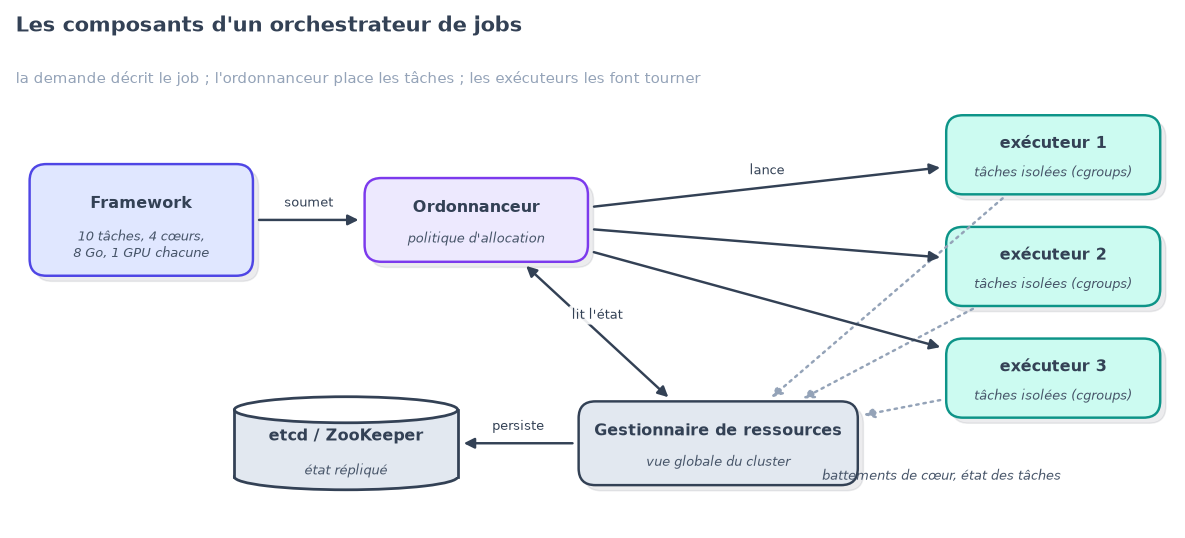

In [15]:
d = Diagram(12.5, 4.6, title="Les composants d'un orchestrateur de jobs",
            subtitle="la demande décrit le job ; l'ordonnanceur place les tâches ; les exécuteurs les font tourner")
d.box("fw", 1.4, 3.3, "Framework", sub="10 tâches, 4 cœurs,\n8 Go, 1 GPU chacune", color=INDIGO, w=2.4, h=1.2)
d.box("sch", 5.0, 3.3, "Ordonnanceur", sub="politique d'allocation", color=VIOLET, w=2.4)
d.box("rm", 7.6, 0.9, "Gestionnaire de ressources", sub="vue globale du cluster", color=SLATE, w=3.0)
d.box("kv", 3.6, 0.9, "etcd / ZooKeeper", sub="état répliqué", color=SLATE, kind="db", w=2.4, h=1.0)
for i, y in enumerate([4.0, 2.8, 1.6]):
    d.box(f"ex{i}", 11.2, y, f"exécuteur {i + 1}", sub="tâches isolées (cgroups)", color=TEAL, w=2.3, h=0.85)
d.arrow("fw", "sch", "soumet")
d.arrow("sch", "rm", "lit l'état", both=True)
d.arrow("rm", "kv", "persiste")
for i in range(3):
    d.arrow("sch", f"ex{i}", "lance" if i == 0 else "")
    d.arrow(f"ex{i}", "rm", "", style="dotted", color=GRAY)
d.note(10.0, 0.55, "battements de cœur, état des tâches", fontsize=8.5)
d.show()

**Allouer, c'est arbitrer.** Le livre prend un petit cluster de 160 cœurs et deux jobs
qui veulent chacun 100 cœurs. On peut donner tout ce qu'on peut au premier puis le reste
au second (FIFO), partager équitablement (80 + 80, en lançant les tâches restantes au fil
des libérations), ou n'exécuter un job que lorsque **toutes** ses tâches peuvent tourner
ensemble (*gang scheduling*, indispensable par exemple quand les tâches se synchronisent
entre elles et ne peuvent pas avancer les unes sans les autres). `BM.simulate_cluster`
compare FIFO et gang scheduling sur un scénario où le problème se voit : un job A
occupe déjà 80 cœurs pour longtemps, le job B demande 100 cœurs, et un petit job C de 40
tâches arrive juste après.

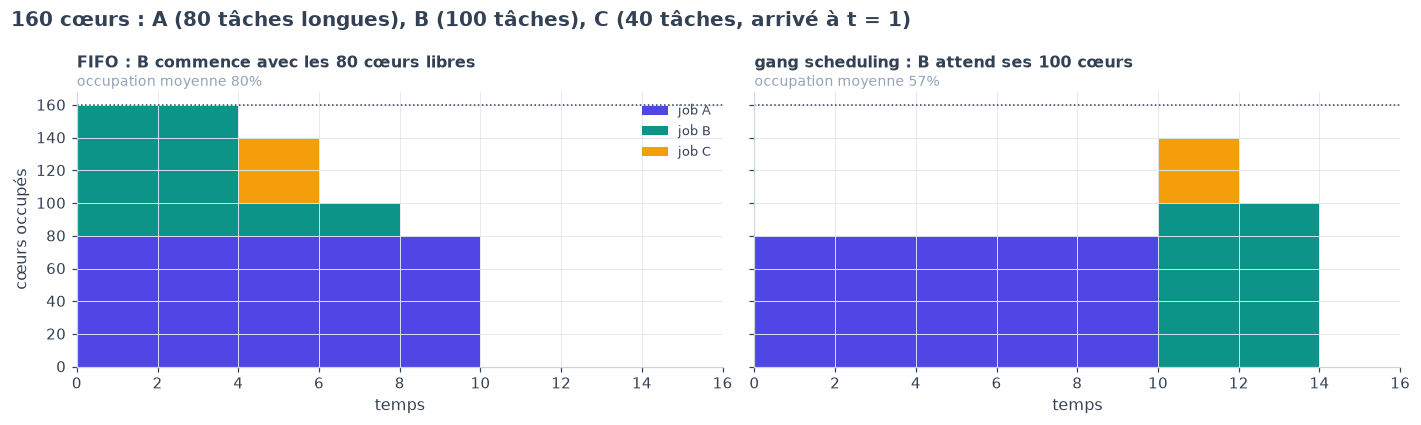

,fin_A,fin_B,fin_C,occupation
fifo,10.0,8.0,6.0,0.80
gang,10.0,14.0,12.0,0.57


In [16]:
jobs = [dict(name="A", arrival=0, tasks=80, duration=10),
        dict(name="B", arrival=0, tasks=100, duration=4, gang=True),
        dict(name="C", arrival=1, tasks=40, duration=2)]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
res_pol = {}
for ax, pol in zip(axes, ["fifo", "gang"]):
    r = BM.simulate_cluster(jobs, 160, pol)
    tl = pd.DataFrame(r["timeline"])
    ax.stackplot(tl.t, tl.A, tl.B, tl.C, colors=[INDIGO, TEAL, AMBER], labels=["job A", "job B", "job C"], step="post")
    occ = (tl.A + tl.B + tl.C)[tl.t < max(r["end"].values())].mean() / 160
    res_pol[pol] = dict(fin_A=r["end"]["A"], fin_B=r["end"]["B"], fin_C=r["end"]["C"], occupation=occ)
    ax.axhline(160, color=SLATE, ls=":", lw=1)
    ax.set_title({"fifo": "FIFO : B commence avec les 80 cœurs libres",
                  "gang": "gang scheduling : B attend ses 100 cœurs"}[pol], fontsize=10.5)
    ax.set_xlabel("temps"); ax.set_xlim(0, 16)
    subtitle(ax, f"occupation moyenne {occ:.0%}")
axes[0].set_ylabel("cœurs occupés"); axes[0].legend(loc="upper right", fontsize=8.5)
finish(fig, "160 cœurs : A (80 tâches longues), B (100 tâches), C (40 tâches, arrivé à t = 1)")
plt.show()
pd.DataFrame(res_pol).T.round(2)

Avec FIFO, B démarre sur les 80 cœurs libres et finit ses 20 dernières tâches plus
tard ; C se glisse dès que des cœurs se libèrent. Avec le gang scheduling, les 80 cœurs
libres sont **réservés** à B jusqu'à ce que A libère les siens : ils restent inoccupés
pendant 10 unités de temps, l'occupation chute, et B comme C finissent bien plus tard. Ne
pas réserver aurait un autre défaut : des jobs plus petits prendraient les cœurs au fil
de l'eau et B risquerait d'attendre indéfiniment (**famine**) ; si plusieurs jobs
réservaient des cœurs en même temps, ils pourraient même s'**interbloquer**. Préempter
des tâches de A pour faire de la place est une troisième option, qui gaspille le travail
déjà fait. Trouver l'allocation optimale d'un grand nombre de jobs est un problème
**NP-difficile** : les ordonnanceurs emploient des heuristiques (FIFO, files à
priorités, quotas par équipe, empaquetage, DRF).

**DRF (*dominant resource fairness*).** Quand les tâches demandent plusieurs ressources
en proportions différentes, « équitable » devient ambigu. DRF égalise la **part
dominante** de chaque utilisateur, c'est-à-dire la plus grande fraction qu'il consomme
parmi toutes les ressources. Exemple de l'article original : 9 cœurs et 18 Go ; les
tâches de A demandent (1 cœur, 4 Go), celles de B (3 cœurs, 1 Go).

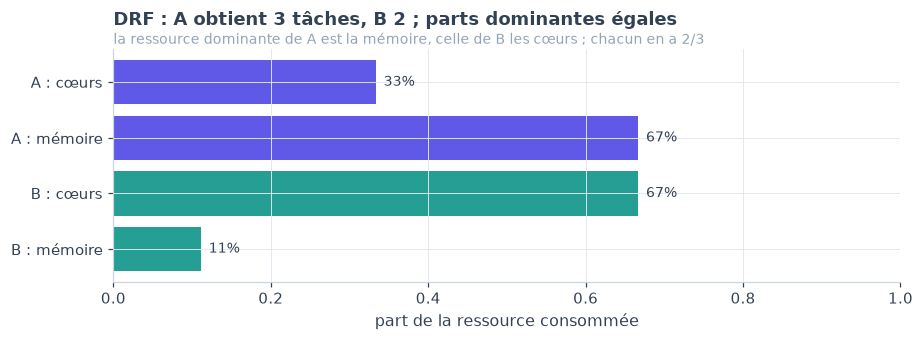

In [17]:
r = BM.drf([9, 18], {"A": [1, 4], "B": [3, 1]})
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for i, (u, dem, c) in enumerate([("A", [1, 4], INDIGO), ("B", [3, 1], TEAL)]):
    parts = np.array(dem) * r["tasks"][u] / np.array([9, 18])
    ax.barh([f"{u} : cœurs", f"{u} : mémoire"], parts, color=c, alpha=0.9)
    for j, v in enumerate(parts):
        ax.text(v + 0.01, 2 * i + j, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlim(0, 1); ax.invert_yaxis()
ax.set_xlabel("part de la ressource consommée")
ax.set_title(f"DRF : A obtient {r['tasks']['A']} tâches, B {r['tasks']['B']} ; parts dominantes égales")
subtitle(ax, "la ressource dominante de A est la mémoire, celle de B les cœurs ; chacun en a 2/3")
plt.tight_layout(); plt.show()

> **À retenir.** Un orchestrateur réunit des exécuteurs par nœud, un gestionnaire de
> ressources (vue globale) et un ordonnanceur. Allouer un cluster partagé oppose équité
> et efficacité (attente des petits jobs, réservation et cœurs inoccupés, famine,
> préemption) ; l'optimum étant hors d'atteinte, on emploie des heuristiques comme FIFO,
> les quotas ou DRF.

## Synthèse

- Un framework de lots distribué est un système d'exploitation de cluster : stockage
  distribué, ordonnancement, programmes qui se passent des données.
- Le **DFS** découpe les fichiers en gros blocs répliqués sur plusieurs racks ; un
  service de métadonnées les localise ; les copies permettent la **localité** (lancer la
  tâche près de ses données). Les **codes d'effacement** offrent la même durabilité
  pour bien moins de disque. Dans le cloud, les **magasins d'objets** remplacent souvent le DFS : objets immuables, pas de renommage atomique, calcul et stockage séparés.
- Un **workflow** est un DAG de jobs dont les sorties sont matérialisées ; son
  ordonnanceur relance les échecs et permet de recalculer seulement ce qui dépend d'un
  job bogué.
- Les tâches sont **relancées** individuellement après une panne ou une préemption ; le
  coût d'une interruption croît exponentiellement avec la durée des tâches. Allouer les ressources d'un cluster partagé est un compromis entre équité et efficacité, résolu par des heuristiques (FIFO, quotas, DRF, gang scheduling).
- Le cours 3 entre dans un job : le modèle **MapReduce** et le **shuffle**. Les liens :
  réplication au chapitre 6, architectures sans partage au chapitre 2,
  pannes et réseaux non fiables au chapitre 9.